<a href="https://colab.research.google.com/github/shivansh11s/Process-Guard-AI/blob/main/ProcessGuardAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Step 1: Import all the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Set some visual styles for our plots
sns.set_style('whitegrid')
plt.style.use('fivethirtyeight')

# Ignore warnings for a cleaner output
warnings.filterwarnings('ignore')

# Step 2: Load the Red Wine Quality dataset directly from the trusted UCI repository URL
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
print("Libraries imported successfully!")
try:
    # We need to use a semicolon (;) as the separator for this specific file
    df = pd.read_csv(url, sep=';')
    print("Dataset 'Red Wine Quality' loaded successfully!")
    print("\nHere's a quick look at your new data:")
    # Display the first 5 rows of the dataset
    print(df.head())
    print(f"\nTotal rows in the dataset: {len(df)}")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Libraries imported successfully!
New Dataset 'Red Wine Quality' loaded successfully!

Here's a quick look at your new data:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0               

In [ ]:
# Get a summary of the dataset (data types, non-null counts)
print("--- Data Info ---")
df.info()

print("\n\n--- Statistical Summary ---")
# Get a statistical overview of the data (mean, std, min, max, etc.)
print(df.describe())

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


--- Statistical Summary ---
       fixed acidity  volatile acidity  citric acid  residual sugar  \
count  

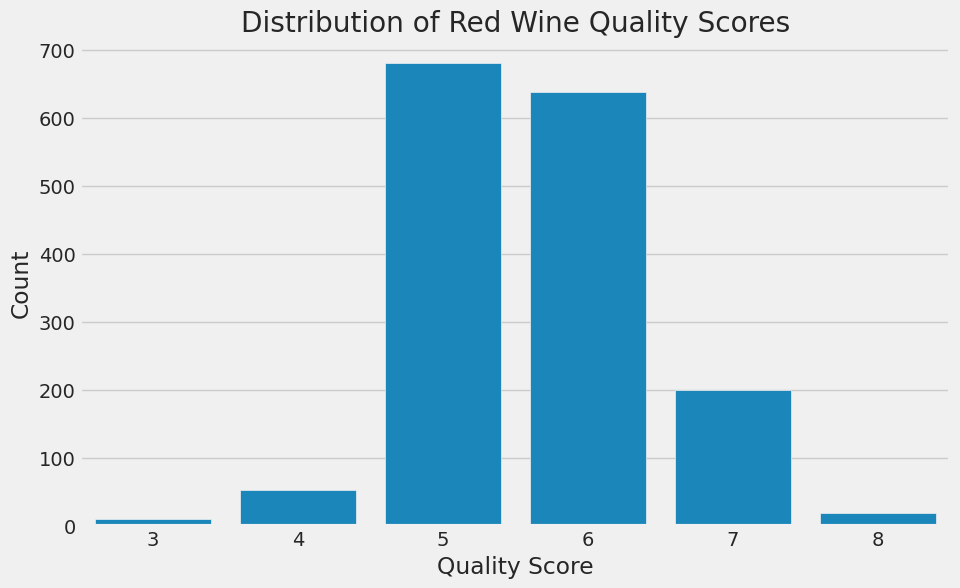

In [ ]:
# Visualize the distribution of the wine quality scores
plt.figure(figsize=(10, 6))
sns.countplot(x='quality', data=df)
plt.title('Distribution of Red Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.show()

In [ ]:
# Creating a new binary column 'quality_class'
# 1 for 'Good' quality (score 7 or higher)
# 0 for 'Bad' quality (score below 7)
df['quality_class'] = df['quality'].apply(lambda x: 1 if x >= 7 else 0)

# Check the new distribution
print("Value counts for our new 'quality_class' column:")
print(df['quality_class'].value_counts())

Value counts for our new 'quality_class' column:
quality_class
0    1382
1     217
Name: count, dtype: int64


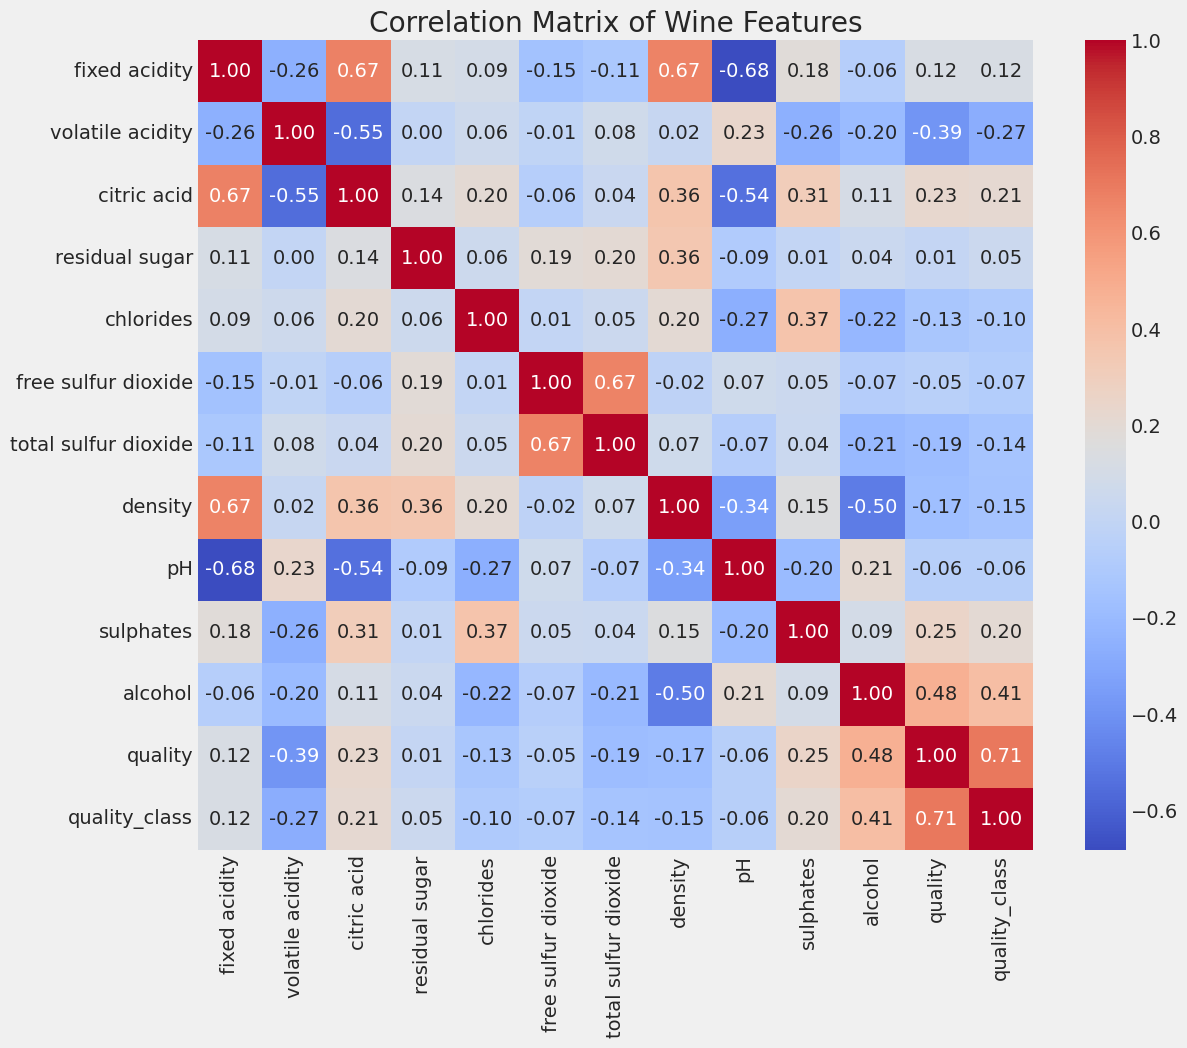

In [ ]:
# Calculate the correlation matrix
correlation_matrix = df.corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Wine Features')
plt.show()

In [ ]:
# Import the necessary tools from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- Part A: Separate Features (X) and Target (y) ---

# X contains all the chemical properties. We drop the original 'quality' column
# and our new 'quality_class' target column.
X = df.drop(['quality', 'quality_class'], axis=1)

# y is our target variable, which is the 'quality_class' column.
y = df['quality_class']

print("Features (X) and Target (y) have been separated.")
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)


# --- Part B: Split Data into Training and Testing Sets ---

# We split the data into 80% for training and 20% for testing.
# The 'random_state' ensures we get the same split every time we run the code.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("\nData has been split into training and testing sets.")
print("Training set size:", len(X_train))
print("Testing set size:", len(X_test))


# --- Part C: Scale the Features ---

# We use StandardScaler to ensure all features are on a similar scale.
# This helps the model learn more effectively.
scaler = StandardScaler()

# We 'fit' the scaler ONLY on the training data to learn the scaling parameters (mean, std).
# Then we 'transform' both the training and testing data using those parameters.
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeatures have been scaled successfully.")

Features (X) and Target (y) have been separated.
Shape of X: (1599, 11)
Shape of y: (1599,)

Data has been split into training and testing sets.
Training set size: 1279
Testing set size: 320

Features have been scaled successfully.


Starting model training...
Model training completed!

Making predictions on the test set...

Model Accuracy: 94.06%

Classification Report:
                  precision    recall  f1-score   support

 Bad Quality (0)       0.95      0.99      0.97       277
Good Quality (1)       0.88      0.65      0.75        43

        accuracy                           0.94       320
       macro avg       0.91      0.82      0.86       320
    weighted avg       0.94      0.94      0.94       320


Confusion Matrix:


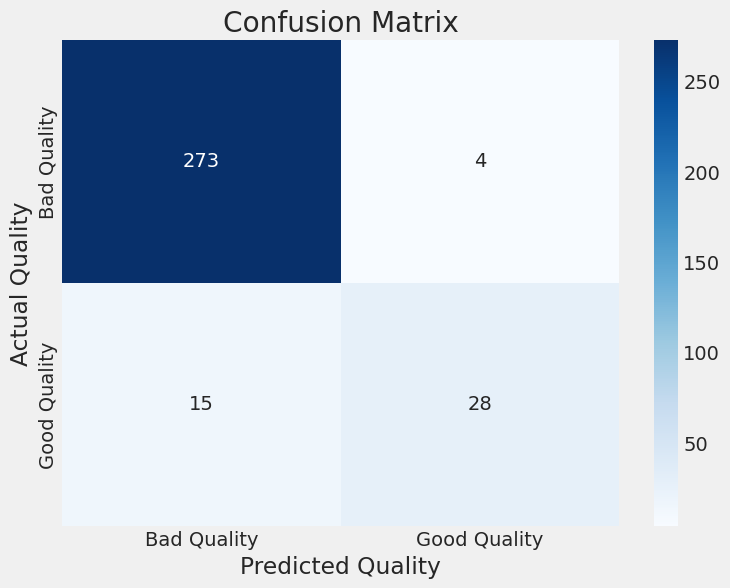

In [ ]:
# Import the XGBoost Classifier and the tools for evaluation
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# --- Part A: Initialize and Train the Model ---

# Create an instance of the XGBClassifier
# 'random_state' ensures that the results are reproducible
xgb_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')

print("Starting model training...")

# Train the model on our scaled training data
xgb_model.fit(X_train_scaled, y_train)

print("Model training completed!")


# --- Part B: Make Predictions on the Test Data ---

# Use the trained model to predict the quality of the unseen test set
y_pred = xgb_model.predict(X_test_scaled)

print("\nMaking predictions on the test set...")


# --- Part C: Evaluate Model Performance ---

# 1. Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy: {accuracy * 100:.2f}%")

# 2. Display a Detailed Classification Report
print("\nClassification Report:")
# 'target_names' helps label our classes in the report
print(classification_report(y_test, y_pred, target_names=['Bad Quality (0)', 'Good Quality (1)']))

# 3. Visualize a Confusion Matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Bad Quality', 'Good Quality'],
            yticklabels=['Bad Quality', 'Good Quality'])
plt.xlabel('Predicted Quality')
plt.ylabel('Actual Quality')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# --- Part B: Create a Predictive Function ---

def predict_wine_quality(wine_sample):
    """
    This function takes a single sample of wine data,
    scales it, predicts its quality, and returns the
    prediction along with the confidence probability.
    """
    # The input 'wine_sample' is a single row (pandas Series).
    # We need to convert it to a DataFrame to scale it.
    wine_sample_df = pd.DataFrame(wine_sample).transpose()

    # Scale the sample using the same scaler we used for training
    wine_sample_scaled = scaler.transform(wine_sample_df)

    # Use predict_proba to get the confidence scores
    # It returns probabilities for [Class 0, Class 1]
    prediction_proba = xgb_model.predict_proba(wine_sample_scaled)

    # Get the probability of the 'Good Quality' class (Class 1)
    good_quality_prob = prediction_proba[0][1]

    # Get the final prediction (0 or 1)
    prediction = xgb_model.predict(wine_sample_scaled)[0]

    return prediction, good_quality_prob


# --- Part C: Simulate the Dashboard on a Sample Wine ---

# Let's take a single sample from our test set to simulate a 'new batch'
sample = X_test.iloc[21]
# Get the prediction and probability using our function
predicted_class, quality_percent = predict_wine_quality(sample)

# --- Display the Final Output ---
print("--- Real-Time Quality Prediction Dashboard ---")
print("\nInput Process Parameters for this Batch:")
print(sample)
print("\n-------------------------------------------------")
print("\nModel Prediction:")

if predicted_class == 1:
    print("  -> Final Quality: GOOD")
else:
    print("  -> Final Quality: BAD")

# Print the confidence score you wanted
print(f"  -> Quality Score (Confidence): {quality_percent * 100:.2f}%")
print("-------------------------------------------------")

--- Real-Time Quality Prediction Dashboard ---

Input Process Parameters for this Batch:
fixed acidity            9.10000
volatile acidity         0.30000
citric acid              0.41000
residual sugar           2.00000
chlorides                0.06800
free sulfur dioxide     10.00000
total sulfur dioxide    24.00000
density                  0.99523
pH                       3.27000
sulphates                0.85000
alcohol                 11.70000
Name: 1107, dtype: float64

-------------------------------------------------

Model Prediction:
  -> Final Quality: GOOD
  -> Quality Score (Confidence): 99.33%
-------------------------------------------------


In [ ]:
import pandas as pd

#creating our own custom data for testing

custom_wine_data = {
    'fixed acidity': 8.5,
    'volatile acidity': 0.35,
    'citric acid': 0.45,
    'residual sugar': 2.0,
    'chlorides': 0.075,
    'free sulfur dioxide': 15.0,
    'total sulfur dioxide': 40.0,
    'density': 0.9955,
    'pH': 3.4,
    'sulphates': 0.85,
    'alcohol': 12.5
}

# --- Step 2: Convert to the Correct Format ---
custom_sample = pd.Series(custom_wine_data)


# --- Step 3: Get the Prediction ---
# We use the same 'predict_wine_quality' function as before.
predicted_class, quality_percent = predict_wine_quality(custom_sample)


# --- Step 4: Display the Dashboard Output ---
print("--- Custom Batch Quality Prediction ---")
print("\nInput Process Parameters for Your Custom Batch:")
print(custom_sample)
print("\n-------------------------------------------------")
print("\nModel Prediction:")

if predicted_class == 1:
    print("  -> Final Quality: GOOD")
else:
    print("  -> Final Quality: BAD")

print(f"  -> Quality Score (Confidence): {quality_percent * 100:.2f}%")
print("-------------------------------------------------")

--- Custom Batch Quality Prediction ---

Input Process Parameters for Your Custom Batch:
fixed acidity            8.5000
volatile acidity         0.3500
citric acid              0.4500
residual sugar           2.0000
chlorides                0.0750
free sulfur dioxide     15.0000
total sulfur dioxide    40.0000
density                  0.9955
pH                       3.4000
sulphates                0.8500
alcohol                 12.5000
dtype: float64

-------------------------------------------------

Model Prediction:
  -> Final Quality: GOOD
  -> Quality Score (Confidence): 74.63%
-------------------------------------------------
